Dataset Shape: (5000, 20)

First 5 Rows:
      Post_ID            Timestamp   Platform Content_Type  Category  Likes  \
0  POST_04552  2024-01-01 01:42:00  Instagram     Carousel  Business   8287   
1  POST_02171  2024-01-01 05:05:00   LinkedIn     Document    Health   1711   
2  POST_00210  2024-01-01 09:18:00  Instagram     Carousel      Food   1527   
3  POST_01548  2024-01-01 10:58:00   Facebook        Video    Sports    535   
4  POST_01350  2024-01-01 13:12:00  Instagram        Photo   Fitness   9706   

   Comments  Shares  Views  Saves  Follower_Count  Engagement_Rate  \
0       247      51  29502     20          223080             3.85   
1        27     247  24538    139          312647             0.63   
2       191       7   5460    359          220737             0.78   
3       178     433  68246    740          428935             0.27   
4        35     118  25782    611           64384            15.31   

   Hour_of_Day Day_of_Week  Hashtag_Count  Content_Length Senti

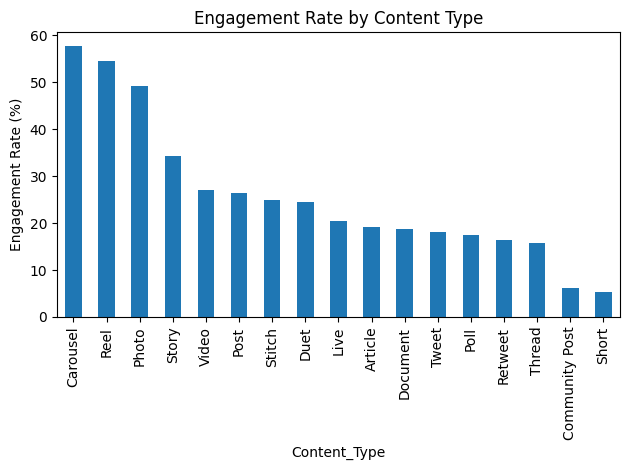


Engagement by Platform:
Platform
Instagram    50.86
Facebook     28.23
TikTok       26.07
LinkedIn     17.92
Twitter      16.80
YouTube       8.57
Name: Engagement_Rate, dtype: float64


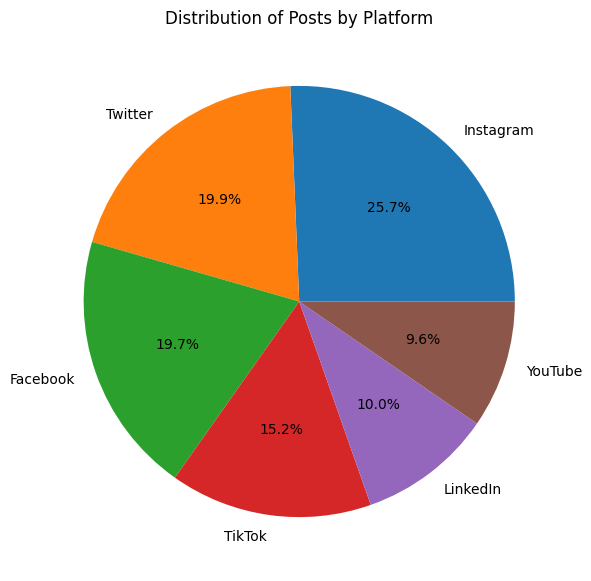

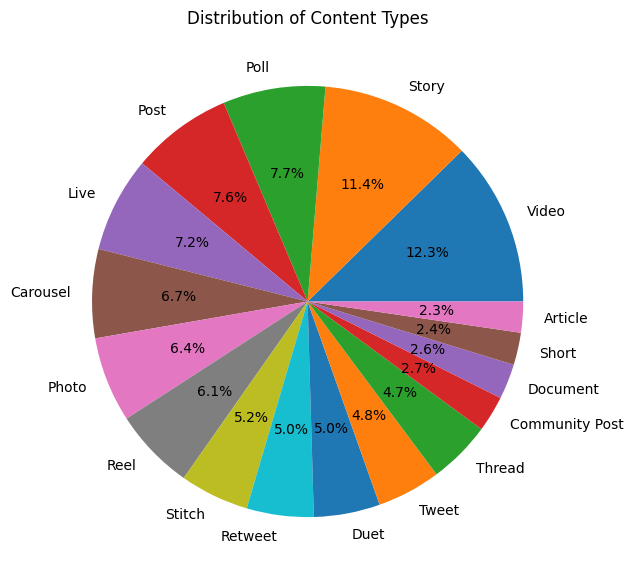


Engagement by Day:
Day_of_Week
Friday       29.69
Monday       24.65
Saturday     27.46
Sunday       33.16
Thursday     27.45
Tuesday      29.18
Wednesday    28.14
Name: Engagement_Rate, dtype: float64


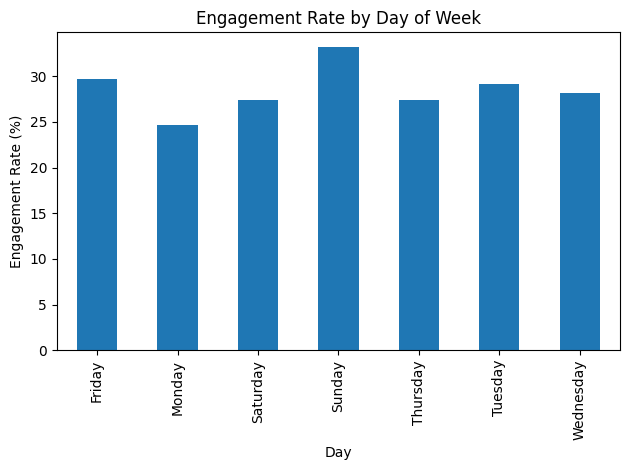

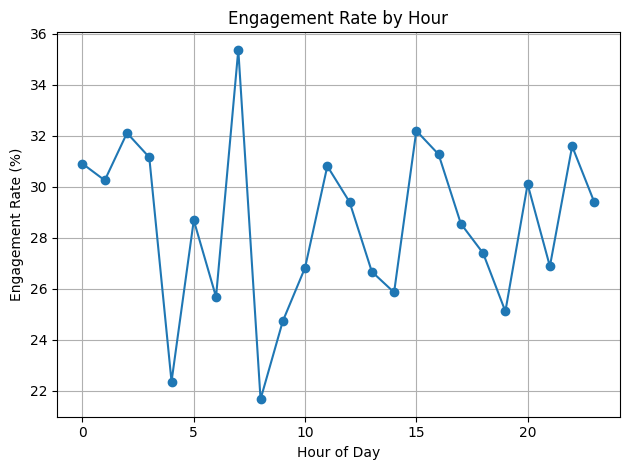

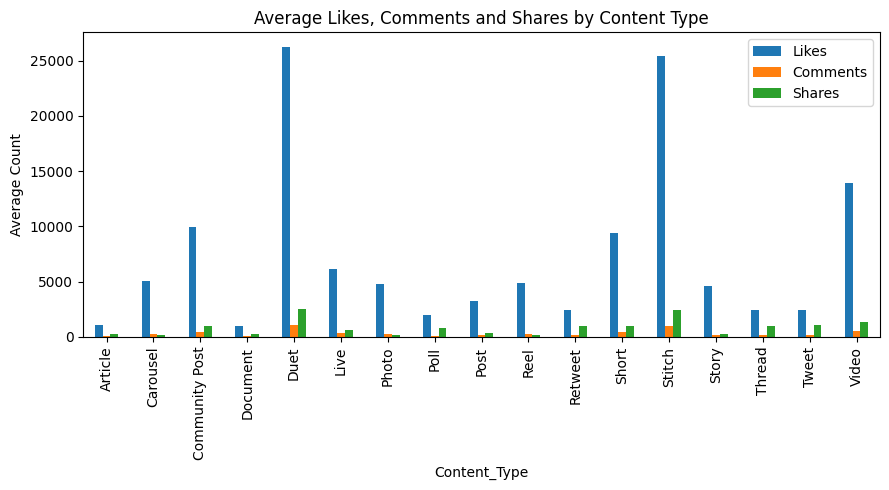


FINAL REPORT
Total Posts: 5000
Average Engagement Rate: 28.52 %
Best Content Type: Carousel
Best Platform: Instagram
Best Day: Sunday
Best Hour: 7


In [24]:
# 1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load Dataset
df = pd.read_csv("/content/social_media_engagement_dataset.csv")

# 3. Clean Data
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# 4. Calculate Engagement Rate
df["Engagement_Rate"] = (
    (df["Likes"] + df["Comments"] + df["Shares"])
    / df["Views"].replace(0, float("nan"))
) * 100

# 5. Top 10 Posts
top_posts = df.sort_values(
    "Engagement_Rate", ascending=False
)

print("\nTop 10 Posts:")
print(top_posts[[
    "Post_ID", "Platform", "Content_Type",
    "Likes", "Comments", "Shares", "Engagement_Rate"
]].head(10))

# 6. Engagement by Content Type
content_analysis = df.groupby(
    "Content_Type"
)["Engagement_Rate"].mean().sort_values(ascending=False)

print("\nEngagement by Content Type:")
print(content_analysis.round(2))

# Chart 1: Bar Chart
content_analysis.plot(kind="bar")
plt.title("Engagement Rate by Content Type")
plt.ylabel("Engagement Rate (%)")
plt.tight_layout()
plt.show()

# 7. Engagement by Platform
platform_analysis = df.groupby(
    "Platform"
)["Engagement_Rate"].mean().sort_values(ascending=False)

print("\nEngagement by Platform:")
print(platform_analysis.round(2))

# Chart 2: Platform Pie Chart
platform_counts = df["Platform"].value_counts()

platform_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)
plt.title("Distribution of Posts by Platform")
plt.ylabel("")
plt.show()

# Chart 3: Content Type Pie Chart
content_counts = df["Content_Type"].value_counts()

content_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)
plt.title("Distribution of Content Types")
plt.ylabel("")
plt.show()

# 8. Engagement by Day of Week
day_analysis = df.groupby(
    "Day_of_Week"
)["Engagement_Rate"].mean()

print("\nEngagement by Day:")
print(day_analysis.round(2))

# Chart 4: Day of Week Bar Chart
day_analysis.plot(kind="bar")
plt.title("Engagement Rate by Day of Week")
plt.xlabel("Day")
plt.ylabel("Engagement Rate (%)")
plt.tight_layout()
plt.show()

# 9. Engagement by Hour
hour_analysis = df.groupby(
    "Hour_of_Day"
)["Engagement_Rate"].mean().sort_index()

# Chart 5: Hourly Line Chart
hour_analysis.plot(kind="line", marker="o")
plt.title("Engagement Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Engagement Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

# 10. Average Likes, Comments and Shares
interaction_data = df.groupby("Content_Type")[
    ["Likes", "Comments", "Shares"]
].mean()

# Chart 6: Interaction Comparison
interaction_data.plot(kind="bar", figsize=(9, 5))
plt.title("Average Likes, Comments and Shares by Content Type")
plt.ylabel("Average Count")
plt.tight_layout()
plt.show()

# 11. Final Report
print("\nFINAL REPORT")
print("Total Posts:", len(df))
print(
    "Average Engagement Rate:",
    round(df["Engagement_Rate"].mean(), 2), "%"
)
print("Best Content Type:", content_analysis.idxmax())
print("Best Platform:", platform_analysis.idxmax())
print("Best Day:", day_analysis.idxmax())
print("Best Hour:", hour_analysis.idxmax())